/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Results:
Classifier: Multinomial Naive Bayes
Accuracy: 0.8576
Precision: 0.9101
Recall: 0.9044
F1 Score: 0.9072
Confusion Matrix:
[[13933  1472]
 [ 1377  3218]]


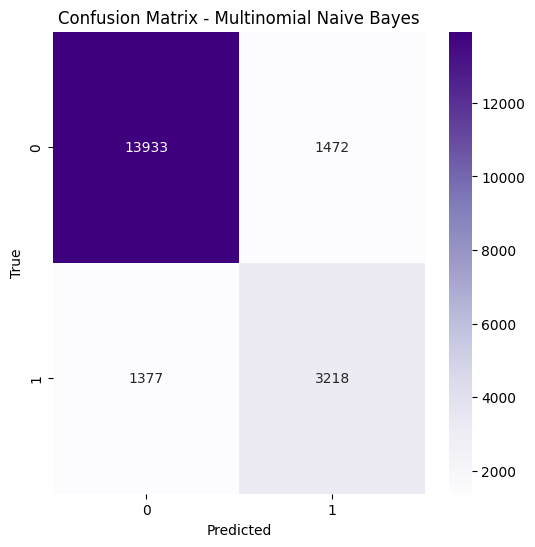

Classifier: Logistic Regression
Accuracy: 0.8750
Precision: 0.9009
Recall: 0.9413
F1 Score: 0.9207
Confusion Matrix:
[[14501   904]
 [ 1595  3000]]


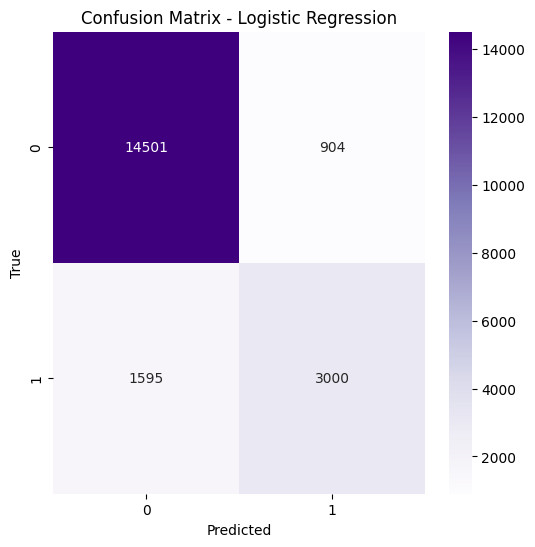

Classifier: Support Vector Classifier
Accuracy: 0.8829
Precision: 0.8888
Recall: 0.9693
F1 Score: 0.9273
Confusion Matrix:
[[14932   473]
 [ 1869  2726]]


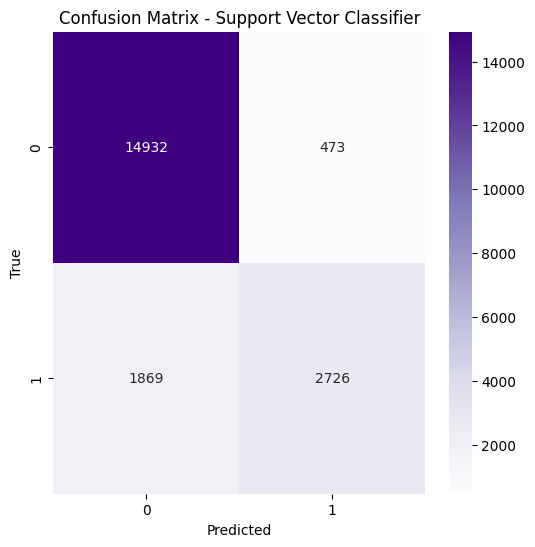

Classifier: Decision Tree Classifier
Accuracy: 0.8152
Precision: 0.8782
Recall: 0.8824
F1 Score: 0.8803
Confusion Matrix:
[[13594  1811]
 [ 1886  2709]]


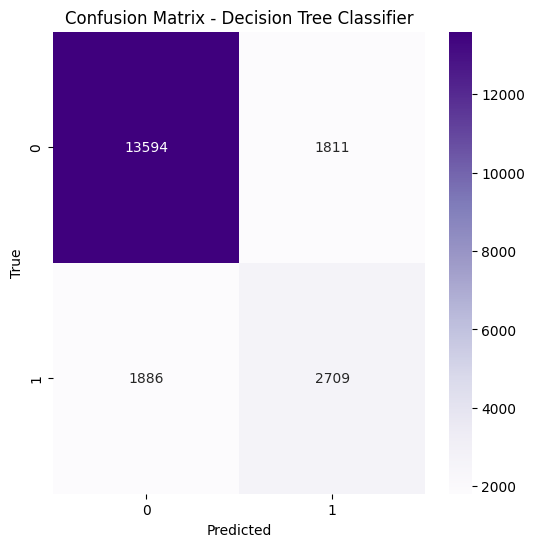

Classifier: Random Forest Classifier
Accuracy: 0.8681
Precision: 0.8656
Recall: 0.9812
F1 Score: 0.9198
Confusion Matrix:
[[15116   289]
 [ 2348  2247]]


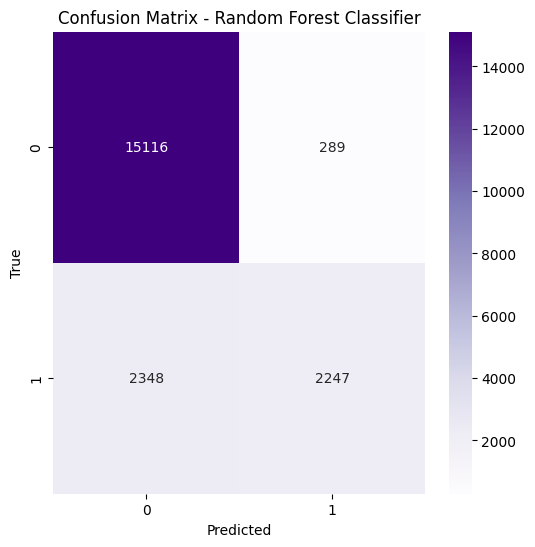

Classifier: Gradient Boosting Classifier
Accuracy: 0.8119
Precision: 0.8114
Recall: 0.9847
F1 Score: 0.8897
Confusion Matrix:
[[15170   235]
 [ 3527  1068]]


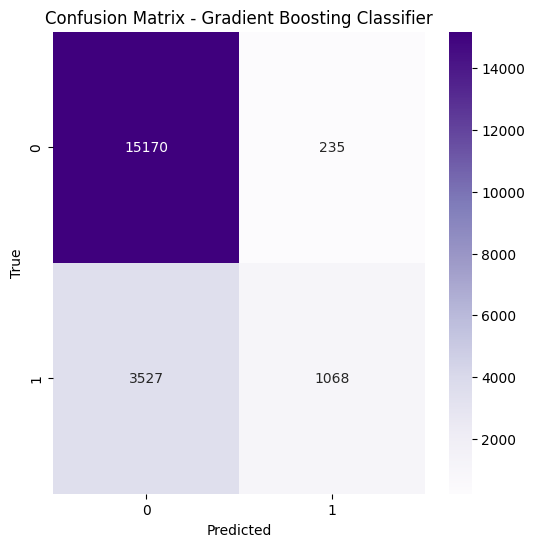

Best Classifier: Support Vector Classifier


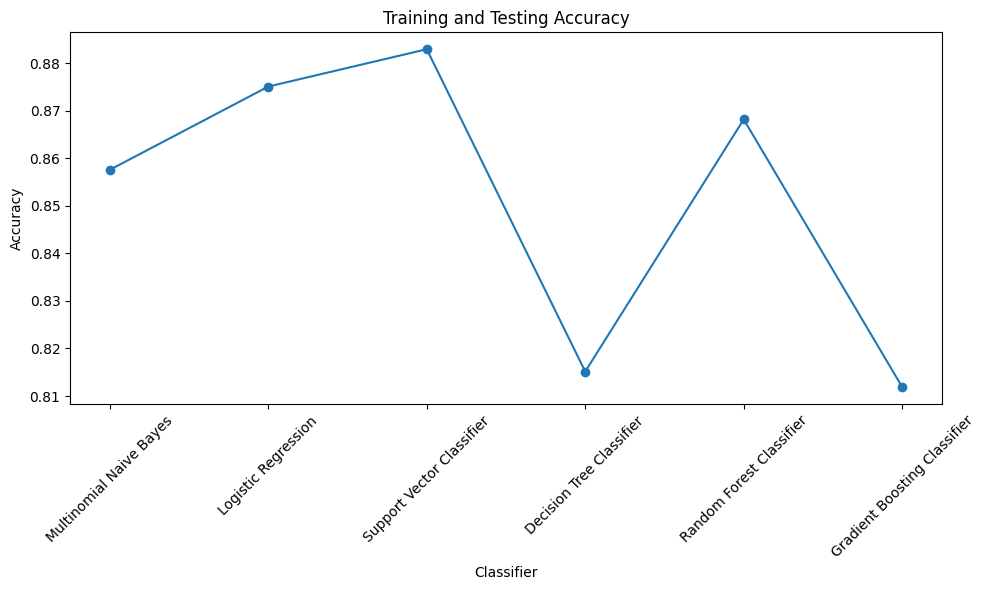

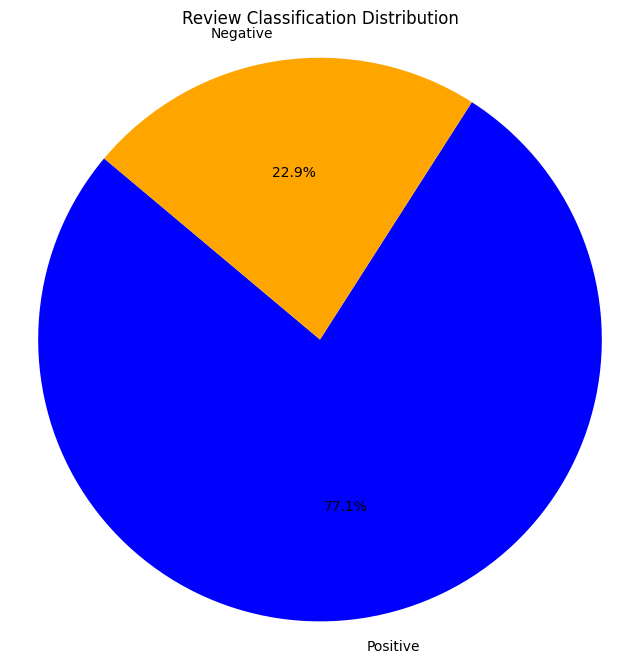

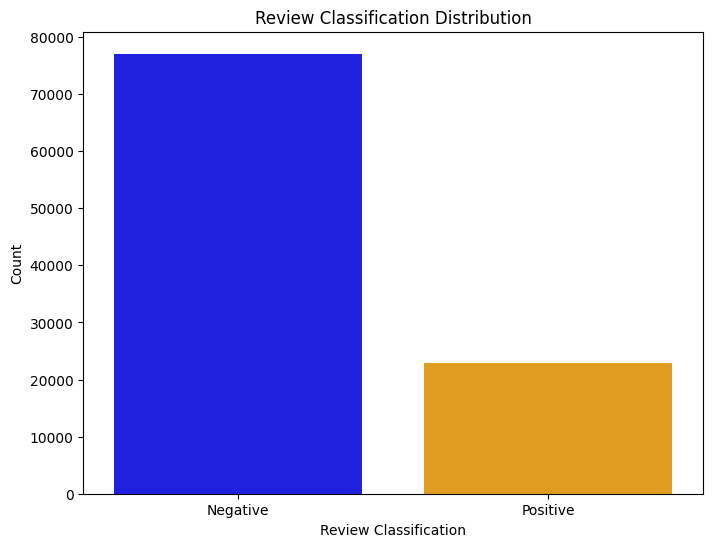

In [22]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
data_path = "/content/sample_data/amazon Food Reviews 100k Dataset.csv"
df = pd.read_csv(data_path)

# Preprocessing function
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    words = nltk.word_tokenize(text)
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

df['cleaned_reviews'] = df['Review'].apply(preprocess_text)

# Apply label encoding
label_encoder = LabelEncoder()
df['label'] = np.where(df['Rating'] > 3, 'Positive', 'Negative')

# Splitting the dataset
X = df['cleaned_reviews']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Vectorization (using CountVectorizer)
vectorizer = CountVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Define classifiers
classifiers = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(),
    "Support Vector Classifier": SVC(),
    "Decision Tree Classifier": DecisionTreeClassifier(),
    "Random Forest Classifier": RandomForestClassifier(),
    "Gradient Boosting Classifier": GradientBoostingClassifier()
}

# Training and evaluation loop
results = {}
for name, classifier in classifiers.items():
    classifier.fit(X_train_vec, y_train)
    y_pred = classifier.predict(X_test_vec)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label='Positive')
    recall = recall_score(y_test, y_pred, pos_label='Positive')
    f1 = f1_score(y_test, y_pred, pos_label='Positive')
    conf_matrix = confusion_matrix(y_test, y_pred, labels=['Positive', 'Negative'])

    results[name] = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": conf_matrix
    }

# Print results and best classifier
best_classifier = max(results, key=lambda x: results[x]["accuracy"])
print("Results:")
for name, metrics in results.items():
    print(f"Classifier: {name}")
    print(f"Accuracy: {metrics['accuracy']:.4f}")
    print(f"Precision: {metrics['precision']:.4f}")
    print(f"Recall: {metrics['recall']:.4f}")
    print(f"F1 Score: {metrics['f1']:.4f}")
    print(f"Confusion Matrix:\n{metrics['confusion_matrix']}")
    print("=" * 50)

    # Plot confusion matrix in purple
    plt.figure(figsize=(6, 6))
    sns.heatmap(metrics['confusion_matrix'], annot=True, cmap='Purples', fmt='g')
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

# Print best classifier
print(f"Best Classifier: {best_classifier}")

# Plot training and testing accuracy
plt.figure(figsize=(10, 6))
plt.plot(results.keys(), [results[classifier]["accuracy"] for classifier in results], marker='o')
plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.title("Training and Testing Accuracy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Pie chart for review classification
review_counts = df['label'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(review_counts, labels=review_counts.index, autopct='%1.1f%%', startangle=140, colors=['blue', 'orange'])
plt.title("Review Classification Distribution")
plt.axis('equal')
plt.show()

# Bar graph for review classification
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='label', palette=['blue', 'orange'])
plt.title("Review Classification Distribution")
plt.xlabel("Review Classification")
plt.ylabel("Count")
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.show()

